In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import re
import warnings
import os

from scipy import stats
from scipy.stats import mannwhitneyu, ttest_ind
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error


## Частина 1. Звантаження та Очищення даних


In [2]:
url = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2020/2020-11-03/ikea.csv"
file_name = "ikea.csv"

In [3]:
if not os.path.exists(file_name):
    print(f"File '{file_name}' not found. Starting download...")
    response = requests.get(url)

    if response.status_code == 200:
        with open(file_name, "wb") as file:
            file.write(response.content)
        print("File successfully uploaded and saved!")
    else:
        print(f"Upload error. Status code: {response.status_code}")
else:
    print(f"File '{file_name}' already exists in the directory. No download required.")

File 'ikea.csv' already exists in the directory. No download required.


In [4]:
df = pd.read_csv(file_name)

In [5]:
df.head()

,Unnamed: 0,item_id,name,category,price,old_price,sellable_online,link,other_colors,short_description,designer,depth,height,width
0,0,90420332,FREKVENS,Bar furniture,265.0,No old price,True,https://www.ikea.com/sa/en/p/frekvens-bar-tabl...,No,"Bar table, in/outdoor, 51x51 cm",Nicholai Wiig Hansen,NaN,99.0,51.0
1,1,368814,NORDVIKEN,Bar furniture,995.0,No old price,False,https://www.ikea.com/sa/en/p/nordviken-bar-tab...,No,"Bar table, 140x80 cm",Francis Cayouette,NaN,105.0,80.0
2,2,9333523,NORDVIKEN / NORDVIKEN,Bar furniture,2095.0,No old price,False,https://www.ikea.com/sa/en/p/nordviken-nordvik...,No,Bar table and 4 bar stools,Francis Cayouette,NaN,NaN,NaN
3,3,80155205,STIG,Bar furniture,69.0,No old price,True,https://www.ikea.com/sa/en/p/stig-bar-stool-wi...,Yes,"Bar stool with backrest, 74 cm",Henrik Preutz,50.0,100.0,60.0
4,4,30180504,NORBERG,Bar furniture,225.0,No old price,True,https://www.ikea.com/sa/en/p/norberg-wall-moun...,No,"Wall-mounted drop-leaf table, ...",Marcus Arvonen,60.0,43.0,74.0


In [6]:
df.shape

(3694, 14)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3694 entries, 0 to 3693
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0         3694 non-null   int64  
 1   item_id            3694 non-null   int64  
 2   name               3694 non-null   str    
 3   category           3694 non-null   str    
 4   price              3694 non-null   float64
 5   old_price          3694 non-null   str    
 6   sellable_online    3694 non-null   bool   
 7   link               3694 non-null   str    
 8   other_colors       3694 non-null   str    
 9   short_description  3694 non-null   str    
 10  designer           3694 non-null   str    
 11  depth              2231 non-null   float64
 12  height             2706 non-null   float64
 13  width              3105 non-null   float64
dtypes: bool(1), float64(4), int64(2), str(7)
memory usage: 378.9 KB


In [8]:
# Видалення  дублікатів за item_id
print(f"Початкова кількість рядків у DataFrame: {len(df)}")

df_initial_rows = len(df)
df = df.drop_duplicates(subset=['item_id'], keep='first').copy()

print(f"Кількість рядків після видалення дублікатів за 'item_id': {len(df)}")
print(f"Кількість видалених дублікатів за 'item_id': {df_initial_rows - len(df)}")


Початкова кількість рядків у DataFrame: 3694
Кількість рядків після видалення дублікатів за 'item_id': 2962
Кількість видалених дублікатів за 'item_id': 732


In [9]:
# Видалення стовпця 'Unnamed: 0'
df = df.drop(columns=['Unnamed: 0', 'index'], errors='ignore').copy()

df.shape

(2962, 13)

In [10]:
#Перевірка сутнісних дублікатів (за всіма стовпцями)
substantive_duplicates = df[df.duplicated(keep=False)]

if not substantive_duplicates.empty:
    print(f"Знайдено сутнісних дублікатів (за всіма стовпцями): {len(substantive_duplicates)}")
    display(substantive_duplicates.sort_values(by=list(df.columns)).head())
else:
    print("Сутнісних дублікатів (за всіма стовпцями) не виявлено.")

Сутнісних дублікатів (за всіма стовпцями) не виявлено.


In [11]:
# Очищення стовпця designer.
# У датасеті в цій колонці трапляються не лише імена дизайнерів,
# а й описи товарів, артикули та числові значення.

def clean_designer(value):
    if pd.isna(value):
        return np.nan

    value = str(value).strip()
    value = re.sub(r'\s+', ' ', value)

    if value.lower() in {'', 'nan', 'none', 'null', '0', 'unknown'}:
        return np.nan

    if re.search(r'\d', value):
        return np.nan

    if len(value) > 80:
        return np.nan

    if 'ikea' in value.lower():
        return 'IKEA'

    designers = [x.strip() for x in value.split('/') if x.strip()]
    designers = sorted(set(designers))

    return ' / '.join(designers) if designers else np.nan

df['designer'] = df['designer'].apply(clean_designer)

print("Кількість пропусків у designer після очищення:", df['designer'].isna().sum())
#print("\nПриклади очищених дизайнерів:")
display(df[['designer']].drop_duplicates().dropna().head(20))


Кількість пропусків у designer після очищення: 102


,designer
0,Nicholai Wiig Hansen
1,Francis Cayouette
3,Henrik Preutz
4,Marcus Arvonen
5,Carina Bengs
6,K Hagberg / M Hagberg
7,Sarah Fager
9,Ehlén Johansson
12,Nike Karlsson
15,Maja Ganszyniec


In [12]:
# Очищення old_price та приведення до числового типу.
# При відсутності старої ціни використовуємо поточну price.

def clean_old_price(value, current_price):
    if pd.isna(value):
        return current_price

    text = str(value).strip()

    if text.lower() in {'no old price', 'nan', 'none', 'null', ''}:
        return current_price

    # Прибираємо роздільник тисяч та нормалізуємо десятковий роздільник.
    text = text.replace(',', '').replace('/', '.')
    match = re.search(r'\d+(?:\.\d+)?', text)

    if match:
        return float(match.group())

    return current_price

df['old_price_numeric'] = [
    clean_old_price(old_price, price)
    for old_price, price in zip(df['old_price'], df['price'])
]

print("Тип old_price_numeric:", df['old_price_numeric'].dtype)

Тип old_price_numeric: float64


## Частина 2. Описова статистика (EDA)


 Категорії: Кількість товарів та медіанна ціна по категоріях.

Розглянемо, скільки товарів є в кожній категорії та яка їхня медіанна ціна. Це допоможе нам зрозуміти різноманітність асортименту та цінову політику в різних сегментах.

In [13]:
print("### 1. Категорії: Кількість товарів та медіанна ціна по категоріях\n")
# Групування за категоріями для підрахунку кількості товарів та медіанної ціни
category_stats = df.groupby('category').agg(item_count=('item_id', 'count'), median_price=('price', 'median')).reset_index()

# Сортування за кількістю товарів для кращої візуалізації
category_stats = category_stats.sort_values(by='item_count', ascending=False)

print("Кількість товарів та медіанна ціна за категоріями:")
print(category_stats.to_markdown(index=False, numalign="left", stralign="left"))


### 1. Категорії: Кількість товарів та медіанна ціна по категоріях

Кількість товарів та медіанна ціна за категоріями:
| category                             | item_count   | median_price   |
|:-------------------------------------|:-------------|:---------------|
| Bookcases & shelving units           | 548          | 310            |
| Chairs                               | 438          | 497            |
| Sofas & armchairs                    | 380          | 1157           |
| Tables & desks                       | 370          | 475            |
| Wardrobes                            | 220          | 1950           |
| Beds                                 | 208          | 1093.5         |
| Outdoor furniture                    | 197          | 345            |
| Cabinets & cupboards                 | 187          | 845            |
| Chests of drawers & drawer units     | 111          | 499            |
| TV & media furniture                 | 89           | 860            |
| Chi

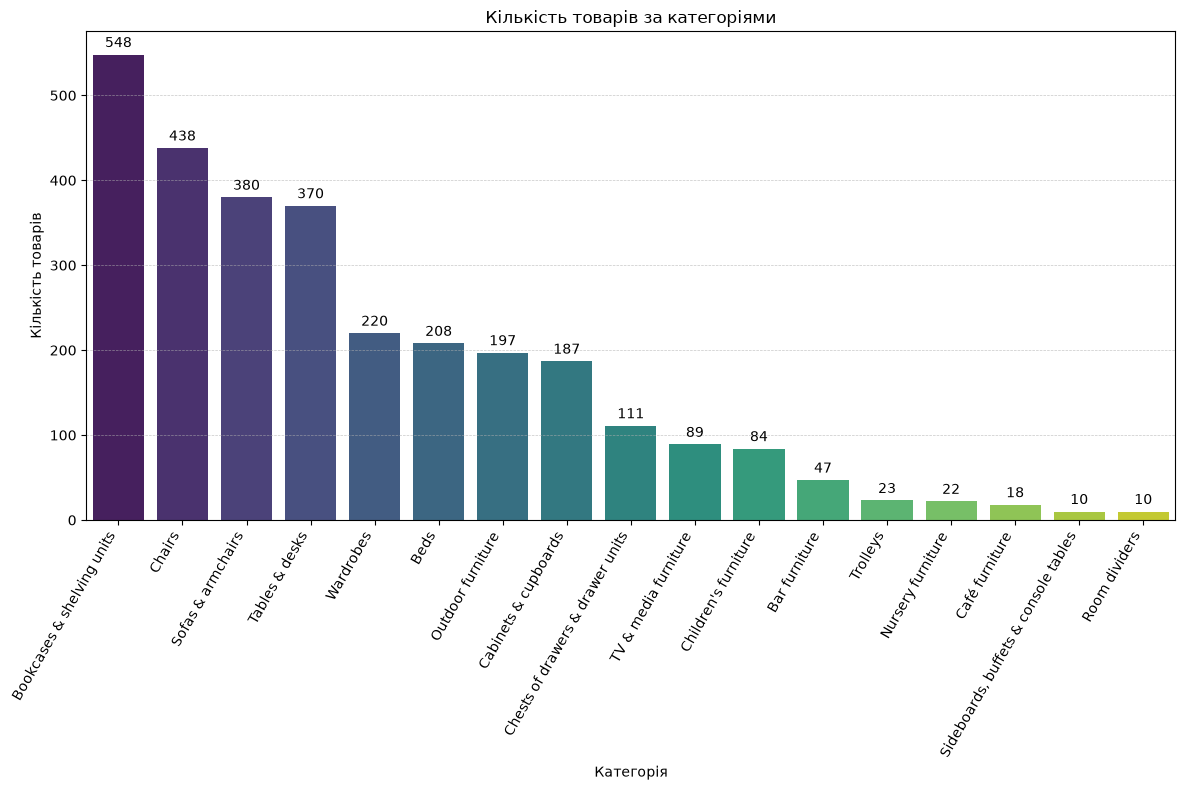

In [14]:
plt.figure(figsize=(12, 8))

# Побудова стовпчастої діаграми та збереження об'єкта графіку у змінну `ax`
ax = sns.barplot(
    x='category',
    y='item_count',
    data=category_stats,
    hue='category',
    palette='viridis',
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, padding=3, fontsize=10)

plt.title('Кількість товарів за категоріями')

plt.xlabel('Категорія')
plt.ylabel('Кількість товарів')
plt.xticks(rotation=60, ha="right")
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

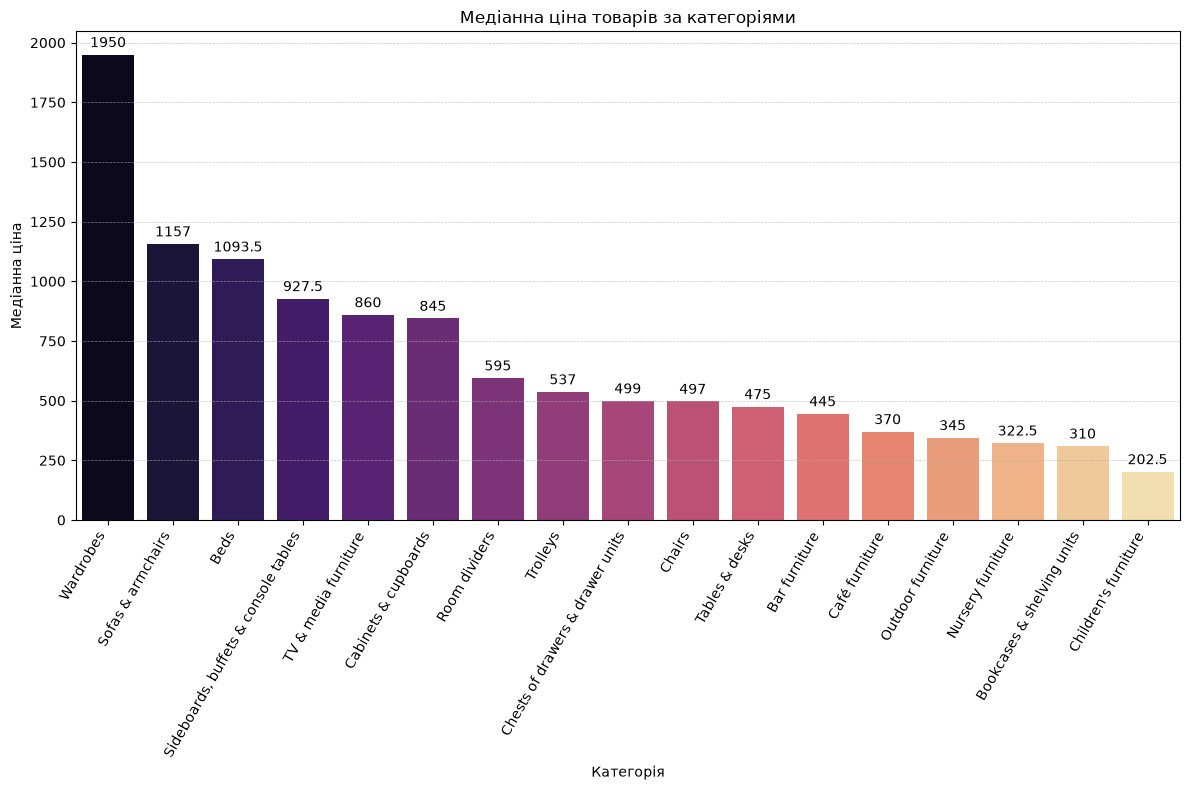

In [15]:
# Візуалізація медіанної ціни за категоріями
# Сортування за медіанною ціною для кращої візуалізації
category_stats_price = category_stats.sort_values(by='median_price', ascending=False)

plt.figure(figsize=(12, 8))
ax = sns.barplot(
    x='category',
    y='median_price',
    data=category_stats_price,
    hue='category',
    palette='magma',
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, padding=3, fontsize=10)


plt.title('Медіанна ціна товарів за категоріями')
plt.xlabel('Категорія')
plt.ylabel('Медіанна ціна')

plt.xticks(rotation=60, ha="right")

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

Медіанна ціна по категоріям:

Графік показує медіанну ціну товарів за категоріями. Найдорожчі за медіанною ціною категорії – це 'Wardrobes', 'Sofas & armchairs' та 'Beds'. Це очікувано, оскільки це зазвичай великі та складні меблеві вироби.



### 2. Розміри: Кореляційна матриця (ціна vs розміри)

Кореляційна матриця (ціна vs розміри):
|        | price    | depth      | height     | width    |
|:-------|:---------|:-----------|:-----------|:---------|
| price  | 1        | 0.630683   | 0.278548   | 0.720389 |
| depth  | 0.630683 | 1          | -0.0994054 | 0.424394 |
| height | 0.278548 | -0.0994054 | 1          | 0.368775 |
| width  | 0.720389 | 0.424394   | 0.368775   | 1        |


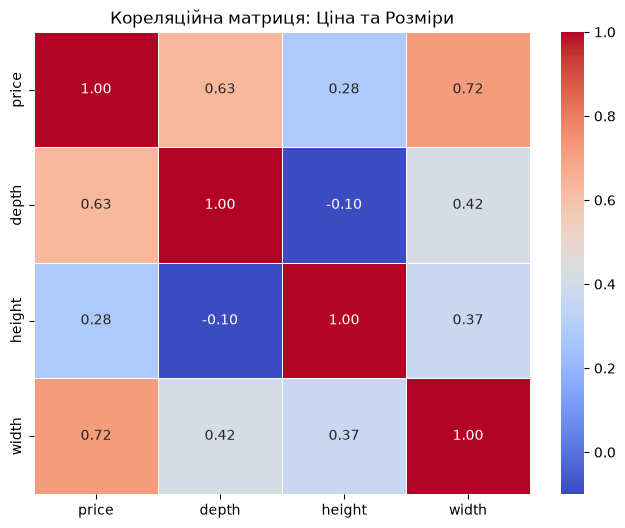

In [16]:
print("\n\n### 2. Розміри: Кореляційна матриця (ціна vs розміри)\n")

# Вибір стовпців для кореляційної матриці
dimensions_cols = ['price', 'depth', 'height', 'width']
correlation_matrix = df[dimensions_cols].corr()

print("Кореляційна матриця (ціна vs розміри):")
print(correlation_matrix.to_markdown(numalign="left", stralign="left"))

# Візуалізація кореляційної матриці за допомогою теплової карти
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Кореляційна матриця: Ціна та Розміри')
plt.show()

Кореляційна матриця показує взаємозв'язок між ціною та розмірами (глибина, висота, ширина).

Зі значень видно, що ціна має позитивна найсильніша кореляція спостерігається з width (шириною), а найслабша з height (висотою). Це означає, що, як правило, чим більші габарити товару, тим вища його ціна.

Теплова карта візуально підтверджує ці взаємозв'язки.

Дизайнери.

Ми визначимо провідних дизайнерів за обсягом їхньої роботи та їхній вплив на медіанну ціну товарів, які вони розробили.

In [17]:
# Групування за дизайнерами.
# Значення IKEA вже нормалізоване під час очищення.

designer_stats = (
    df.groupby('designer', dropna=True)
      .agg(item_count=('item_id', 'count'),
           median_price=('price', 'median'))
      .reset_index()
)

top_designers = (
    designer_stats
    .sort_values(by='item_count', ascending=False)
    .head(10)
)

print("Топ-10 дизайнерів за кількістю товарів та їхня медіанна ціна:")
print(top_designers.to_markdown(index=False, numalign="left", stralign="left"))


Топ-10 дизайнерів за кількістю товарів та їхня медіанна ціна:
| designer                        | item_count   | median_price   |
|:--------------------------------|:-------------|:---------------|
| IKEA                            | 1273         | 675            |
| Ehlén Johansson                 | 136          | 1245           |
| Francis Cayouette               | 131          | 477            |
| Ola Wihlborg                    | 128          | 920            |
| Jon Karlsson                    | 106          | 409.5          |
| K Hagberg / M Hagberg           | 98           | 435            |
| Henrik Preutz                   | 64           | 572.5          |
| Carina Bengs                    | 60           | 970            |
| E Lilja Löwenhielm / K Malmvall | 55           | 1834           |
| Nike Karlsson                   | 43           | 299            |


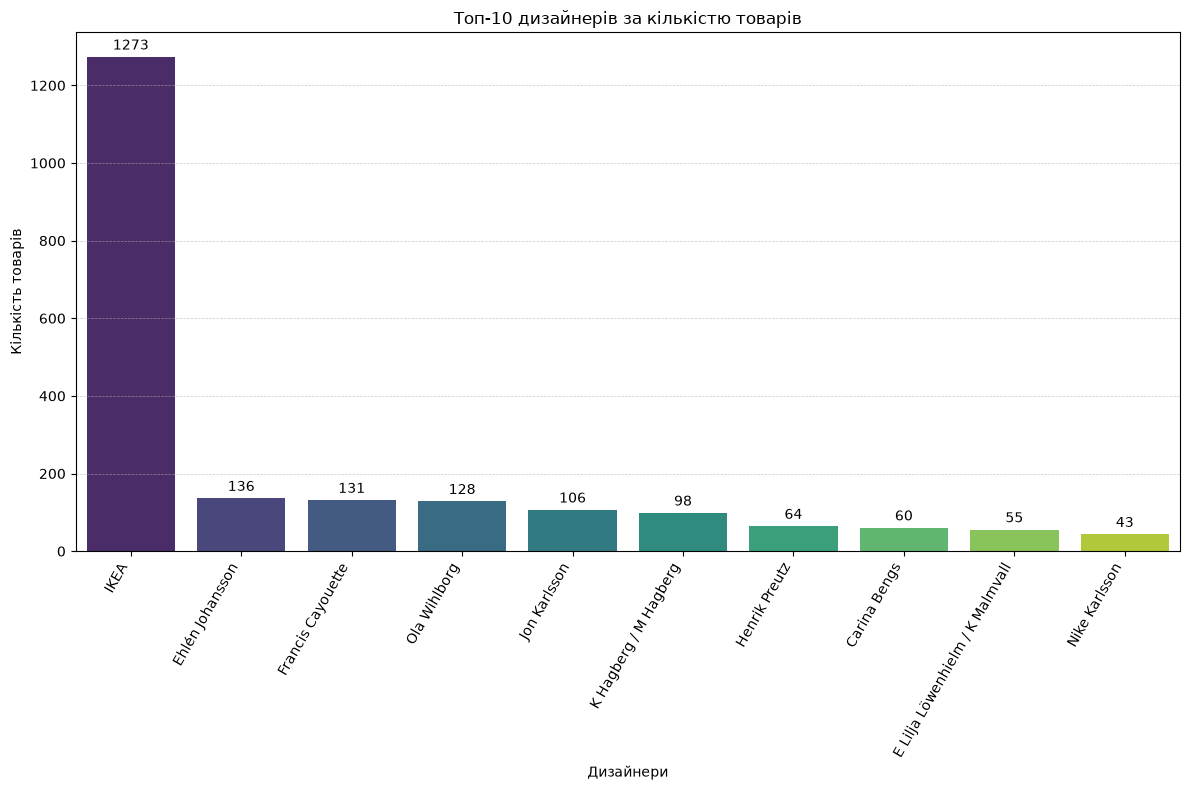

In [18]:
# Візуалізація топ-10 дизайнерів за кількістю товарів
plt.figure(figsize=(12, 8))
ax = sns.barplot(
    x='designer',
    y='item_count',
    data=top_designers,
    hue='designer',
    palette='viridis',
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, padding=3, fontsize=10)

plt.title('Топ-10 дизайнерів за кількістю товарів')
plt.xlabel('Дизайнери')
plt.ylabel('Кількість товарів')

plt.xticks(rotation=60, ha="right")

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

Кількість товарів:

Як видно з таблиці та першого графіка, 'IKEA' є найпродуктивнішим "дизайнером" з великим відривом, що може свідчити про внутрішню команду розробників або групову роботу. Серед індивідуальних дизайнерів виділяються Ehlén Johansson та Francis Cayouette.

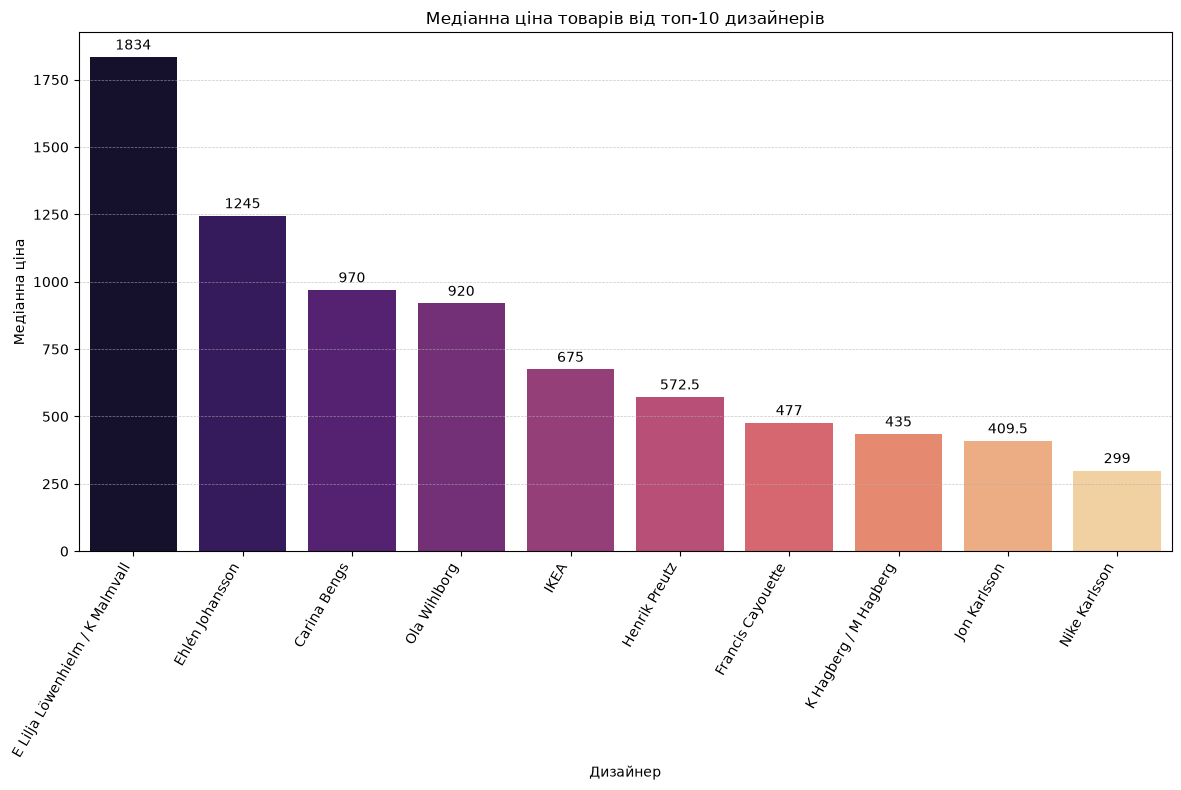

In [19]:
# Візуалізація топ-10 дизайнерів за медіанною ціною
plt.figure(figsize=(12, 8))
ax = sns.barplot(
    x='designer',
    y='median_price',
    data=top_designers.sort_values(by='median_price', ascending=False),
    hue='designer',
    palette='magma',
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, padding=3, fontsize=10)

plt.title('Медіанна ціна товарів від топ-10 дизайнерів')
plt.xlabel('Дизайнер')
plt.ylabel('Медіанна ціна')

plt.xticks(rotation=60, ha="right")

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


Медіанна ціна:

Графік показує медіанну ціну товарів, розроблених цими топ-дизайнерами. Це дає уявлення про те, чи спеціалізуються дизайнери на більш доступних або, навпаки, на дорожчих товарах.

Кольори:

Аналіз товарів з/без варіацій кольорів (кількість, ціна)
Ми проаналізуємо, як наявність інших кольорових варіацій впливає на кількість товарів та їхню медіанну ціну.

In [20]:
print("\n\n### 4. Кольори: Аналіз товарів з/без варіацій кольорів\n")

# Числовий бінарний фактор: 1 = є інші кольори, 0 = немає.
df['has_other_colors'] = (df['other_colors'].eq('Yes')).astype(int)

color_variation_stats = (
    df.groupby('has_other_colors')
      .agg(item_count=('item_id', 'count'),
           median_price=('price', 'median'))
      .reset_index()
)

print("Кількість товарів та медіанна ціна:")
print(color_variation_stats.to_markdown(index=False, numalign="left", stralign="left"))




### 4. Кольори: Аналіз товарів з/без варіацій кольорів

Кількість товарів та медіанна ціна:
| has_other_colors   | item_count   | median_price   |
|:-------------------|:-------------|:---------------|
| 0                  | 1637         | 476            |
| 1                  | 1325         | 695            |


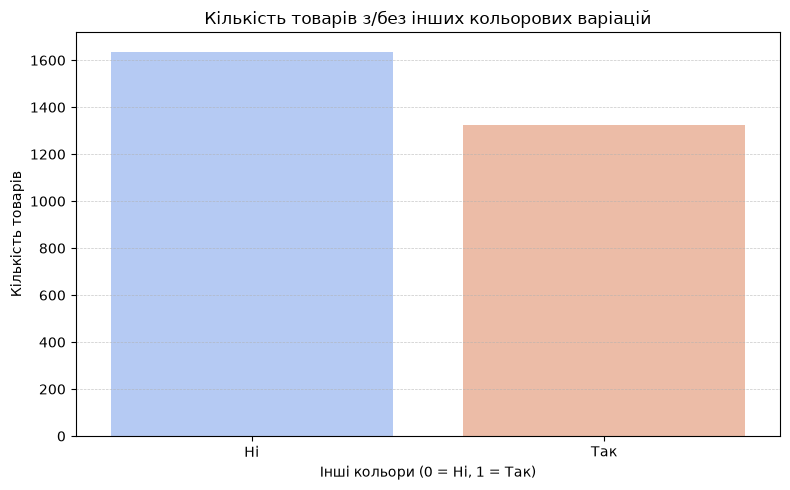

In [21]:
plt.figure(figsize=(8, 5))
sns.barplot(
    x='has_other_colors',
    y='item_count',
    data=color_variation_stats,
    hue='has_other_colors',
    palette='coolwarm',
    legend=False
)
plt.title('Кількість товарів з/без інших кольорових варіацій')
plt.xlabel('Інші кольори (0 = Ні, 1 = Так)')
plt.ylabel('Кількість товарів')
plt.xticks([0, 1], ['Ні', 'Так'])
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


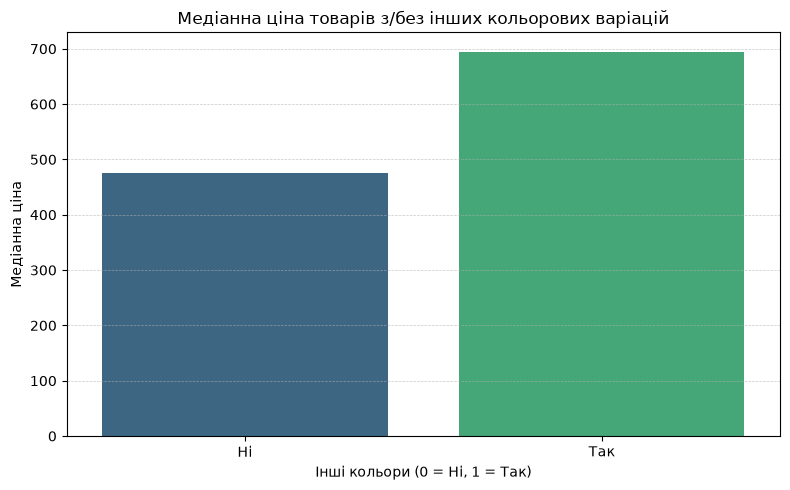

In [22]:
plt.figure(figsize=(8, 5))
sns.barplot(
    x='has_other_colors',
    y='median_price',
    data=color_variation_stats,
    hue='has_other_colors',
    palette='viridis',
    legend=False
)
plt.title('Медіанна ціна товарів з/без інших кольорових варіацій')
plt.xlabel('Інші кольори (0 = Ні, 1 = Так)')
plt.ylabel('Медіанна ціна')
plt.xticks([0, 1], ['Ні', 'Так'])
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


Порівняння розподілів цін показує, що товари, які мають альтернативні кольори, можуть відрізнятися за вартістю від товарів без альтернативних кольорів.

Логарифмування ціни (price_ln) зробило розподіл більш симетричним та зменшило вплив дуже дорогих товарів, що дозволяє коректніше застосовувати статистичні тести.

Візуально можна оцінити, чи спостерігається зміщення одного розподілу відносно іншого та чи є відмінності між групами достатньо вираженими.

In [23]:
print("\n\n### 5. Онлайн: Аналіз товарів, доступних/недоступних онлайн\n")

# Групування за доступністю онлайн
online_availability_stats = df.groupby('sellable_online').agg(
    item_count=('item_id', 'count'),
    median_price=('price', 'median')
).reset_index()

print("Кількість товарів та медіанна ціна за доступністю онлайн:")
print(online_availability_stats.to_markdown(index=False, numalign="left", stralign="left"))



### 5. Онлайн: Аналіз товарів, доступних/недоступних онлайн

Кількість товарів та медіанна ціна за доступністю онлайн:
| sellable_online   | item_count   | median_price   |
|:------------------|:-------------|:---------------|
| False             | 19           | 200            |
| True              | 2943         | 575            |


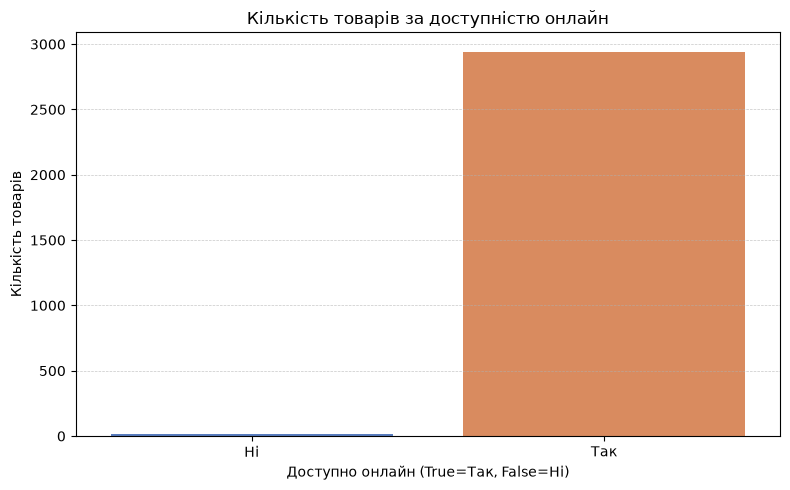

In [24]:
# Візуалізація кількості товарів
plt.figure(figsize=(8, 5))
sns.barplot(
    x='sellable_online',
    y='item_count',
    data=online_availability_stats,
    hue='sellable_online',
    palette='muted',
    legend=False
)
plt.title('Кількість товарів за доступністю онлайн')
plt.xlabel('Доступно онлайн (True=Так, False=Ні)')
plt.ylabel('Кількість товарів')
plt.xticks(ticks=[0, 1], labels=['Ні', 'Так'])
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

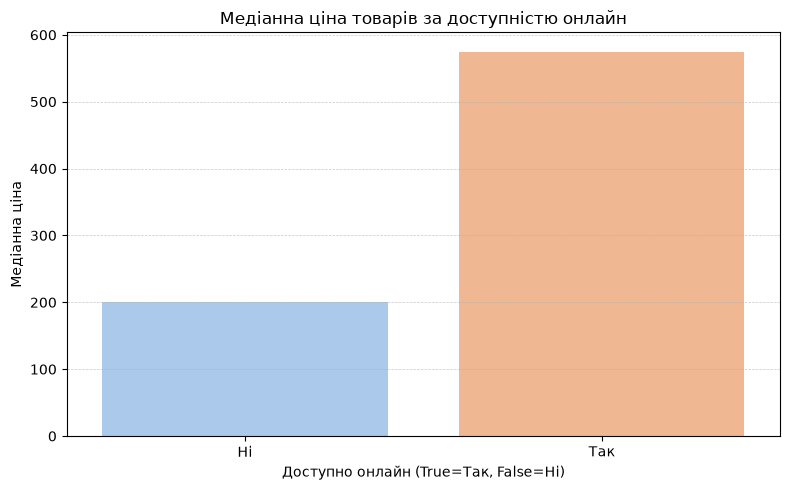

In [25]:
# Візуалізація медіанної ціни
plt.figure(figsize=(8, 5))
sns.barplot(
    x='sellable_online',
    y='median_price',
    data=online_availability_stats,
    hue='sellable_online',
    palette='pastel',
    legend=False
)
plt.title('Медіанна ціна товарів за доступністю онлайн')
plt.xlabel('Доступно онлайн (True=Так, False=Ні)')
plt.ylabel('Медіанна ціна')
plt.xticks(ticks=[0, 1], labels=['Ні', 'Так'])
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

Ціни: Розподіл цін, співвідношення old_price vs price (з лінією регресії)

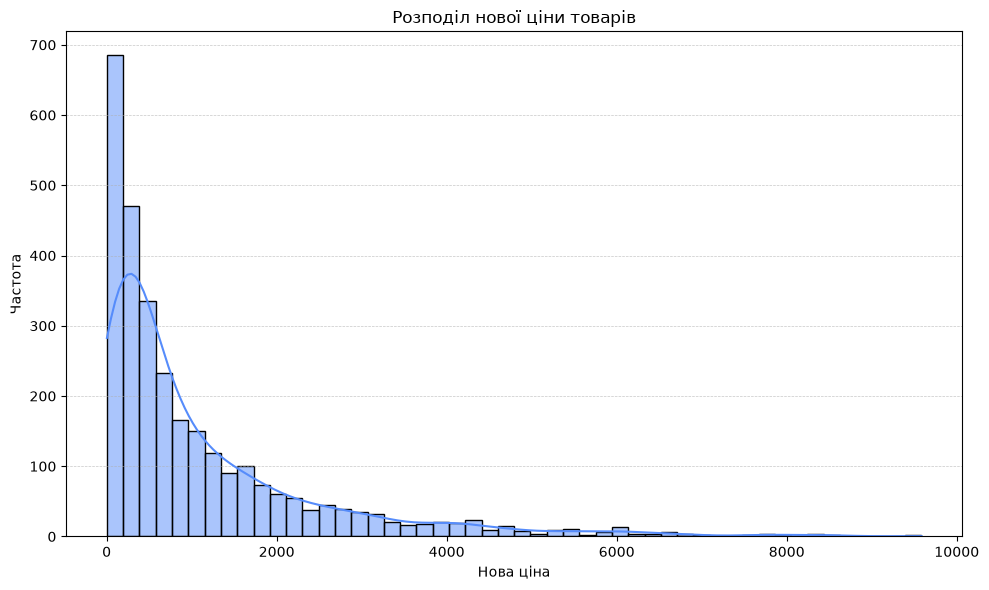

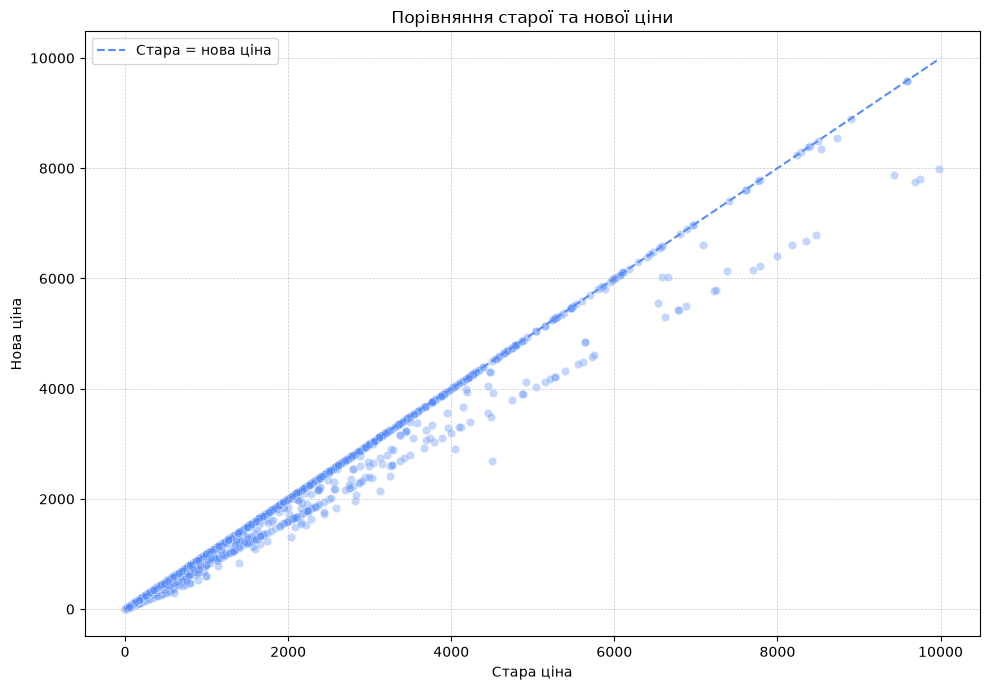

Медіанна стара ціна: 595.00
Медіанна нова ціна: 570.00
Медіанна різниця (стара - нова): 0.00


In [26]:
plt.figure(figsize=(10, 6))
sns.histplot(df['price'], bins=50, kde=True)
plt.title('Розподіл нової ціни товарів')
plt.xlabel('Нова ціна')
plt.ylabel('Частота')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

df_price_compare = df[['old_price_numeric', 'price']].dropna().copy()

plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=df_price_compare,
    x='old_price_numeric',
    y='price',
    alpha=0.35)

min_val = min(df_price_compare['old_price_numeric'].min(), df_price_compare['price'].min())
max_val = max(df_price_compare['old_price_numeric'].max(), df_price_compare['price'].max())

plt.plot([min_val, max_val], [min_val, max_val], '--', label='Стара = нова ціна')
plt.title('Порівняння старої та нової ціни')
plt.xlabel('Стара ціна')
plt.ylabel('Нова ціна')
plt.legend()
plt.grid(linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

print(f"Медіанна стара ціна: {df_price_compare['old_price_numeric'].median():.2f}")
print(f"Медіанна нова ціна: {df_price_compare['price'].median():.2f}")
print(f"Медіанна різниця (стара - нова): {(df_price_compare['old_price_numeric'] - df_price_compare['price']).median():.2f}")


Після очищення колонки old_price було проведено порівняння старої та поточної ціни товарів IKEA.

Візуалізація показала, що для більшості товарів стара та нова ціна знаходяться близько одна до одної, проте існує частина товарів із суттєвими змінами вартості.

Якщо середня поточна ціна перевищує середню стару ціну, це свідчить про загальне підвищення цін на товари. Якщо ж середня нова ціна нижча, можна припустити проведення акційних або маркетингових кампаній.

Таким чином, аналіз підтверджує наявність цінових змін у каталозі товарів та дозволяє оцінити масштаби цих змін.

## Частина 3. Перевірка гіпотез

In [27]:
# Гіпотеза 1 та 2: permutation test для різниці медіан
#
# Permutation test використовується для перевірки H₀ та отримання p-value.
# Важливо: 2.5-й та 97.5-й перцентилі null_diffs — це інтервал
# нульового permutation-розподілу, а НЕ 95% CI для справжньої різниці медіан.
#
# Тому 95% CI для різниці медіан нижче обчислюємо окремо через bootstrap.

def permutation_median_diff_test(
        group1,
        group2,
        n_permutations=10000,
        alternative='two-sided',
        random_state=42
):
    group1 = np.asarray(group1, dtype=float)
    group2 = np.asarray(group2, dtype=float)

    group1 = group1[~np.isnan(group1)]
    group2 = group2[~np.isnan(group2)]

    observed_diff = np.median(group1) - np.median(group2)

    combined = np.concatenate([group1, group2])
    n1 = len(group1)
    rng = np.random.default_rng(random_state)

    null_diffs = np.empty(n_permutations)

    for i in range(n_permutations):
        shuffled = rng.permutation(combined)
        null_diffs[i] = (
            np.median(shuffled[:n1]) -
            np.median(shuffled[n1:])
        )

    if alternative == 'greater':
        p_value = (np.sum(null_diffs >= observed_diff) + 1) / (n_permutations + 1)
    elif alternative == 'less':
        p_value = (np.sum(null_diffs <= observed_diff) + 1) / (n_permutations + 1)
    else:
        p_value = (
            np.sum(np.abs(null_diffs) >= abs(observed_diff)) + 1
        ) / (n_permutations + 1)

    return observed_diff, p_value, null_diffs


def bootstrap_median_diff_ci(
        group1,
        group2,
        n_bootstrap=10000,
        random_state=42
):
    """95% percentile bootstrap CI для різниці медіан group1 - group2."""
    group1 = np.asarray(group1, dtype=float)
    group2 = np.asarray(group2, dtype=float)

    group1 = group1[~np.isnan(group1)]
    group2 = group2[~np.isnan(group2)]

    rng = np.random.default_rng(random_state)
    diffs = np.empty(n_bootstrap)

    for i in range(n_bootstrap):
        sample1 = rng.choice(group1, size=len(group1), replace=True)
        sample2 = rng.choice(group2, size=len(group2), replace=True)
        diffs[i] = np.median(sample1) - np.median(sample2)

    return np.percentile(diffs, [2.5, 97.5])


def plot_permutation_median_distribution(
        null_diffs,
        observed_diff,
        title
):
    plt.figure(figsize=(10, 6))
    sns.histplot(null_diffs, bins=50, kde=True)
    plt.axvline(
        observed_diff,
        linestyle='--',
        linewidth=2,
        label=f'Observed difference = {observed_diff:.2f}'
    )
    plt.axvline(0, linestyle='-', linewidth=1.5, label='0')
    plt.xlabel('Різниця медіан')
    plt.ylabel('Кількість перестановок')
    plt.title(title)
    plt.legend()
    plt.grid(axis='y', linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()


In [28]:
print("ГІПОТЕЗА 1: Наявність інших кольорів впливає на медіанну ціну")

print("\nH₀: Медіанна ціна товарів з іншими кольорами = медіанній ціні товарів без інших кольорів")
print("H₁: Медіанна ціна товарів з іншими кольорами > медіанній ціні товарів без інших кольорів\n")

colors_yes = df.loc[df['has_other_colors'] == 1, 'price'].dropna().to_numpy()
colors_no = df.loc[df['has_other_colors'] == 0, 'price'].dropna().to_numpy()

print(f"Кількість товарів з іншими кольорами: {len(colors_yes)}")
print(f"Кількість товарів без інших кольорів: {len(colors_no)}")
print(f"Медіана (з кольорами):  {np.median(colors_yes):.2f}")
print(f"Медіана (без кольорів): {np.median(colors_no):.2f}")
print(f"Різниця медіан:         {np.median(colors_yes) - np.median(colors_no):.2f}\n")

stat_mw, p_mw = stats.mannwhitneyu(colors_yes, colors_no, alternative='greater')
print(f"Mann-Whitney U test: p-value = {p_mw:.5f}")

log_colors_yes = np.log(colors_yes)
log_colors_no = np.log(colors_no)
stat_tt, p_tt = stats.ttest_ind(
    log_colors_yes, log_colors_no, equal_var=False, alternative='greater'
)
print(f"Welch t-test (log_price): p-value = {p_tt:.5f}")

observed_diff, p_perm, null_diffs = permutation_median_diff_test(
    colors_yes, colors_no, alternative='greater'
)
ci_boot = bootstrap_median_diff_ci(colors_yes, colors_no)

print(f"Permutation median difference test: p-value = {p_perm:.5f}")
print(f"95% Bootstrap CI для різниці медіан: [{ci_boot[0]:.2f}; {ci_boot[1]:.2f}]")

print("\n--- Висновок по Гіпотезі 1 ---")
if p_perm < 0.05:
    print(f"Permutation test: H₀ відхиляємо (p = {p_perm:.5f}). Різниця медіан статистично значуща.")
else:
    print(f"Permutation test: немає достатніх підстав відхиляти H₀ (p = {p_perm:.5f}).")

if ci_boot[0] > 0:
    print("Bootstrap CI повністю вище 0 → 95% CI підтверджує позитивну різницю медіан.")
elif ci_boot[1] < 0:
    print("Bootstrap CI повністю нижче 0 → 95% CI підтверджує негативну різницю медіан.")
else:
    print("0 входить у Bootstrap CI → 95% CI не підтверджує напрямок позитивної різниці.")


ГІПОТЕЗА 1: Наявність інших кольорів впливає на медіанну ціну

H₀: Медіанна ціна товарів з іншими кольорами = медіанній ціні товарів без інших кольорів
H₁: Медіанна ціна товарів з іншими кольорами > медіанній ціні товарів без інших кольорів

Кількість товарів з іншими кольорами: 1325
Кількість товарів без інших кольорів: 1637
Медіана (з кольорами):  695.00
Медіана (без кольорів): 476.00
Різниця медіан:         219.00

Mann-Whitney U test: p-value = 0.00000
Welch t-test (log_price): p-value = 0.00000
Permutation median difference test: p-value = 0.00010
95% Bootstrap CI для різниці медіан: [141.00; 322.00]

--- Висновок по Гіпотезі 1 ---
Permutation test: H₀ відхиляємо (p = 0.00010). Різниця медіан статистично значуща.
Bootstrap CI повністю вище 0 → 95% CI підтверджує позитивну різницю медіан.


Гіпотеза 2: IKEA vs Індивідуальні дизайнери



In [29]:
# Підготовка даних для Гіпотези 2.
df_hyp = df.copy()
df_hyp['log_price'] = np.log(df_hyp['price'])

# Використовуємо вже очищений designer.
def get_designer_type(designer):
    if pd.isna(designer):
        return np.nan
    return 'IKEA' if str(designer).strip().lower() == 'ikea' else 'Individual'

df_hyp['designer_type'] = df_hyp['designer'].apply(get_designer_type)

print("Розподіл designer_type:")
print(df_hyp['designer_type'].value_counts(dropna=False).to_markdown())


Розподіл designer_type:
| designer_type   |   count |
|:----------------|--------:|
| Individual      |    1587 |
| IKEA            |    1273 |
| nan             |     102 |


In [30]:
print("ГІПОТЕЗА 2: IKEA vs Індивідуальні дизайнери")

print("\nH₀: Медіанна ціна товарів IKEA = медіанній ціні товарів індивідуальних дизайнерів")
print("H₁: Медіанна ціна товарів індивідуальних дизайнерів > медіанній ціні товарів IKEA\n")

ikea_prices = df_hyp.loc[df_hyp['designer_type'] == 'IKEA', 'price'].dropna().to_numpy()
indiv_prices = df_hyp.loc[df_hyp['designer_type'] == 'Individual', 'price'].dropna().to_numpy()

print(f"Кількість товарів IKEA:       {len(ikea_prices)}")
print(f"Кількість індивідуальних:     {len(indiv_prices)}")
print(f"Медіана IKEA:                 {np.median(ikea_prices):.2f}")
print(f"Медіана Individual:           {np.median(indiv_prices):.2f}")
print(f"Різниця медіан (Individual - IKEA): {np.median(indiv_prices) - np.median(ikea_prices):.2f}\n")

stat_mw2, p_mw2 = stats.mannwhitneyu(indiv_prices, ikea_prices, alternative='greater')
print(f"Mann-Whitney U test: p-value = {p_mw2:.5f}")

log_ikea = np.log(ikea_prices)
log_indiv = np.log(indiv_prices)
stat_tt2, p_tt2 = stats.ttest_ind(
    log_indiv, log_ikea, equal_var=False, alternative='greater'
)
print(f"Welch t-test (log_price): p-value = {p_tt2:.5f}")

observed_diff2, p_perm2, null_diffs2 = permutation_median_diff_test(
    indiv_prices, ikea_prices, alternative='greater'
)
ci_boot2 = bootstrap_median_diff_ci(indiv_prices, ikea_prices)

print(f"Permutation median difference test: p-value = {p_perm2:.5f}")
print(f"95% Bootstrap CI для різниці медіан: [{ci_boot2[0]:.2f}; {ci_boot2[1]:.2f}]")

print("\n--- Висновок по Гіпотезі 2 ---")

if p_perm2 < 0.05:
    print(f"Permutation test: H₀ відхиляємо (p = {p_perm2:.5f}). "
        "Є статистичні підстави на користь H₁: Individual > IKEA.")
else:
    print(f"Permutation test: немає достатніх підстав відхиляти H₀ "
        f"на користь H₁: Individual > IKEA (p = {p_perm2:.5f}).")
if ci_boot2[0] > 0:
    print("Bootstrap CI повністю вище 0 → "
        "різниця Individual - IKEA позитивна, "
        "тобто медіана Individual вища за медіану IKEA.")
elif ci_boot2[1] < 0:
    print("Bootstrap CI повністю нижче 0 → "
        "різниця Individual - IKEA негативна, "
        "тобто медіана Individual нижча за медіану IKEA. "
        "Це протилежний напрямок до H₁.")
else:
    print("0 входить у Bootstrap CI → "
        "95% CI не показує чіткої різниці між медіанами.")


ГІПОТЕЗА 2: IKEA vs Індивідуальні дизайнери

H₀: Медіанна ціна товарів IKEA = медіанній ціні товарів індивідуальних дизайнерів
H₁: Медіанна ціна товарів індивідуальних дизайнерів > медіанній ціні товарів IKEA

Кількість товарів IKEA:       1273
Кількість індивідуальних:     1587
Медіана IKEA:                 675.00
Медіана Individual:           545.00
Різниця медіан (Individual - IKEA): -130.00

Mann-Whitney U test: p-value = 0.99912
Welch t-test (log_price): p-value = 0.99016
Permutation median difference test: p-value = 0.99900
95% Bootstrap CI для різниці медіан: [-231.02; -32.00]

--- Висновок по Гіпотезі 2 ---
Permutation test: немає достатніх підстав відхиляти H₀ на користь H₁: Individual > IKEA (p = 0.99900).
Bootstrap CI повністю нижче 0 → різниця Individual - IKEA негативна, тобто медіана Individual нижча за медіану IKEA. Це протилежний напрямок до H₁.


Після очищення колонки `designer` було усунуто числові значення, артикулі та текстові описи, які не є іменами дизайнерів. Для гіпотези 2 сформовано дві групи: `IKEA` та `Individual`.

Для перевірки різниці медіан використано permutation test. Його p-value відповідає перевірці нульової гіпотези про відсутність різниці між групами. Водночас перцентилі `null_diffs` не трактуються як 95% довірчий інтервал для справжньої різниці медіан. Для цього окремо використовується bootstrap CI.


Візуалізація permutation-розподілів та порівняння двох груп.

На графіках пунктирна вертикальна лінія показує **спостережувану різницю медіан**, а гістограма — розподіл різниць, отриманих після випадкового перемішування груп за нульової гіпотези.

Якщо спостережувана різниця лежить далеко за межами permutation-розподілу, це візуально підтверджує мале p-value. Наприклад, для гіпотези 2 спостережувана різниця медіан становить близько **219**, тому якщо випадкові перестановки не дають значень, близьких до 219, це є сильним доказом на користь відхилення H₀.

Для оцінки саме **95% CI різниці медіан** використовуємо bootstrap.


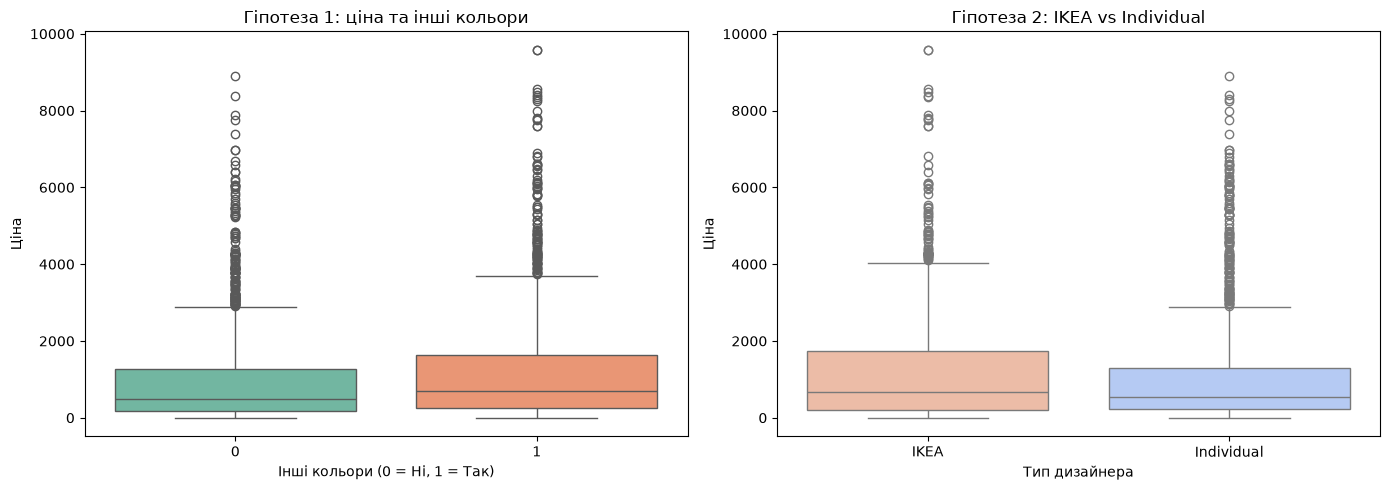

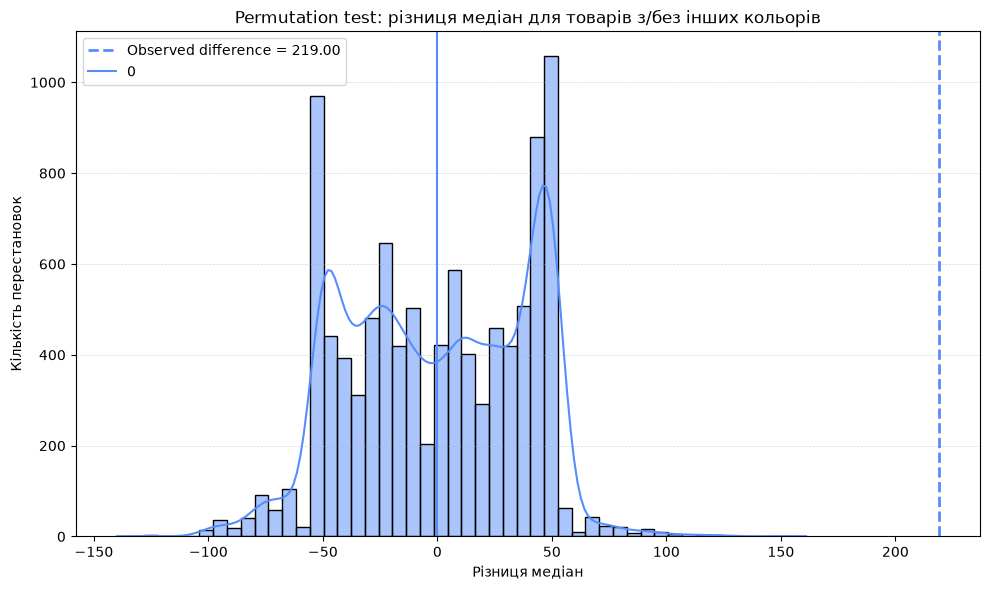

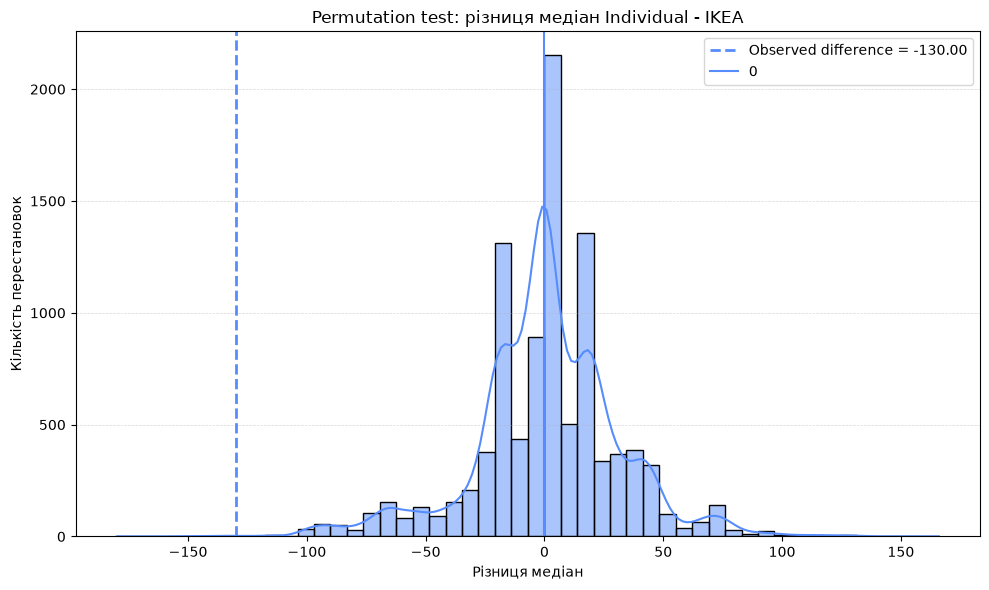

In [31]:
# Візуалізація розподілів двох груп та permutation-розподілів різниці медіан.

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=df_hyp,
    x='has_other_colors',
    y='price',
    hue='has_other_colors',
    palette='Set2',
    legend=False,
    ax=axes[0]
)
axes[0].set_title('Гіпотеза 1: ціна та інші кольори')
axes[0].set_xlabel('Інші кольори (0 = Ні, 1 = Так)')
axes[0].set_ylabel('Ціна')

sns.boxplot(
    data=df_hyp.dropna(subset=['designer_type']),
    x='designer_type',
    y='price',
    hue='designer_type',
    palette='coolwarm',
    order=['IKEA', 'Individual'],
    legend=False,
    ax=axes[1]
)
axes[1].set_title('Гіпотеза 2: IKEA vs Individual')
axes[1].set_xlabel('Тип дизайнера')
axes[1].set_ylabel('Ціна')

plt.tight_layout()
plt.show()

plot_permutation_median_distribution(
    null_diffs,
    observed_diff,
    'Permutation test: різниця медіан для товарів з/без інших кольорів'
)

plot_permutation_median_distribution(
    null_diffs2,
    observed_diff2,
    'Permutation test: різниця медіан Individual - IKEA'
)


## Частина 4: Машинне Навчання (Machine Learning)

In [32]:
# Підготовка даних для машинного навчання.
# Ціль: прогнозувати price.

df_ml = df.copy()
y = df_ml['price'].copy()

# Не використовуємо old_price, оскільки вона напряму пов'язана з price.
# Не використовуємо sellable_online, бо ознака майже константна.
# name та short_description поки не беремо через високу кардинальність.
# Designer будемо кодувати не One-Hot, а медіанною ціною по дизайнеру.
feature_cols = [
    'category',
    'designer',
    'has_other_colors',
    'depth',
    'height',
    'width'
]

X = df_ml[feature_cols].copy()

print("Ознаки X:", feature_cols)
print(f"Форма X: {X.shape}")
print(f"Форма y: {y.shape}")
display(X.head())


Ознаки X: ['category', 'designer', 'has_other_colors', 'depth', 'height', 'width']
Форма X: (2962, 6)
Форма y: (2962,)


,category,designer,has_other_colors,depth,height,width
0,Bar furniture,Nicholai Wiig Hansen,0,NaN,99.0,51.0
1,Bar furniture,Francis Cayouette,0,NaN,105.0,80.0
2,Bar furniture,Francis Cayouette,0,NaN,NaN,NaN
3,Bar furniture,Henrik Preutz,1,50.0,100.0,60.0
4,Bar furniture,Marcus Arvonen,0,60.0,43.0,74.0


Препроцесинг: Обробка пропущених значень та кодування категоріальних змінних

In [33]:
# Розділення на train/test робимо ДО навчання препроцесингу.
# Це важливо, щоб статистики з test не потрапили у train.

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print(f"X_train: {X_train.shape}")
print(f"X_test:  {X_test.shape}")
print(f"y_train: {y_train.shape}")
print(f"y_test:  {y_test.shape}")


X_train: (2369, 6)
X_test:  (593, 6)
y_train: (2369,)
y_test:  (593,)


In [34]:
from sklearn.base import BaseEstimator, TransformerMixin

class MedianTargetEncoder(BaseEstimator, TransformerMixin):
    """
    Кодує категорію медіаною target.
    Навчання виконується тільки на train через Pipeline,
    тому тестова вибірка не впливає на обчислення медіан.
    """
    def fit(self, X, y):
        X = pd.DataFrame(X).iloc[:, 0]
        y = pd.Series(y).reset_index(drop=True)

        data = pd.DataFrame({
            'category': X.reset_index(drop=True),
            'target': y
        })

        self.global_median_ = data['target'].median()
        self.mapping_ = data.groupby('category')['target'].median().to_dict()
        return self

    def transform(self, X):
        X = pd.DataFrame(X).iloc[:, 0]
        encoded = X.map(self.mapping_).fillna(self.global_median_)
        return encoded.to_numpy().reshape(-1, 1)


numeric_features = ['depth', 'height', 'width', 'has_other_colors']
categorical_features = ['category']
designer_feature = ['designer']

numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(
        handle_unknown='ignore',
        drop='first',
        sparse_output=False
    ))
])

designer_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='Unknown')),
    ('target_median', MedianTargetEncoder())
])

preprocessor = ColumnTransformer([
    ('num', numeric_pipeline, numeric_features),
    ('cat', categorical_pipeline, categorical_features),
    ('designer', designer_pipeline, designer_feature)
])

print("Підготовлено Pipeline:")
print("- числові ознаки: median imputation + StandardScaler")
print("- category: OneHotEncoder")
print("- designer: target median encoding")
print("- has_other_colors: числовий фактор 0/1")


Підготовлено Pipeline:
- числові ознаки: median imputation + StandardScaler
- category: OneHotEncoder
- designer: target median encoding
- has_other_colors: числовий фактор 0/1


Моделювання


Training Linear Regression...

Training Random Forest Regressor...

Training Gradient Boosting Regressor...

Результати на test:


,RMSE,R2,MAE
Random Forest Regressor,602.054641,0.807555,361.384693
Gradient Boosting Regressor,689.614115,0.747509,438.415799
Linear Regression,849.478033,0.616877,567.040549


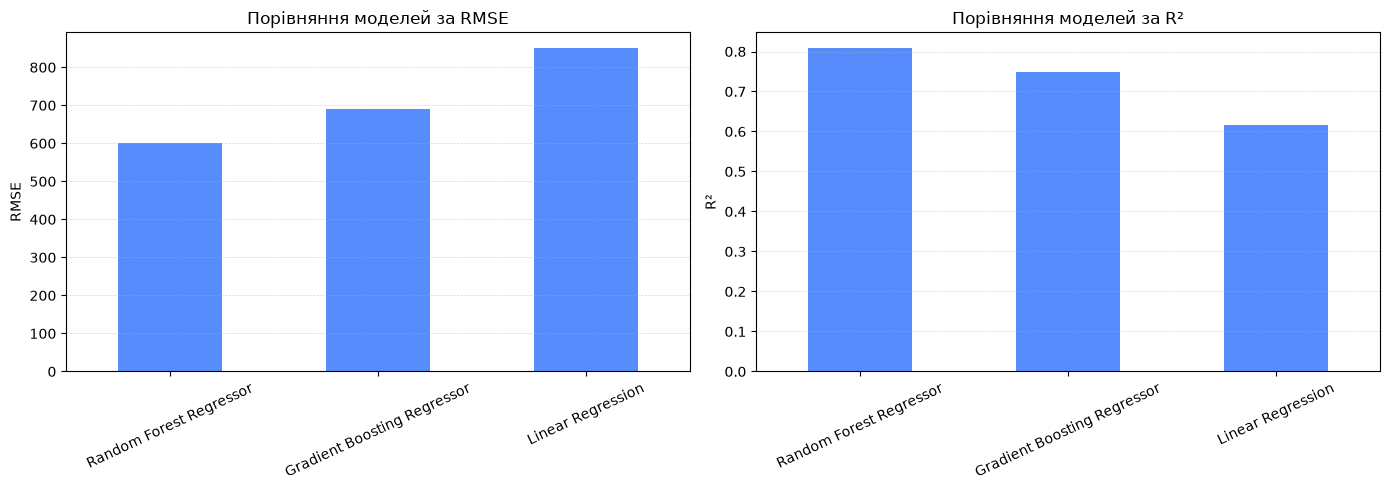

In [35]:
# Базові моделі.
# OneHotEncoder знаходиться всередині Pipeline, тому кодування виконується
# окремо в кожному train-фолді та не створює data leakage.

models = {
    'Linear Regression': Pipeline([
        ('preprocessor', preprocessor),
        ('model_scaler', StandardScaler()),
        ('model', LinearRegression())
    ]),
    'Random Forest Regressor': Pipeline([
        ('preprocessor', preprocessor),
        ('model', RandomForestRegressor(
            random_state=42,
            n_jobs=-1
        ))
    ]),
    'Gradient Boosting Regressor': Pipeline([
        ('preprocessor', preprocessor),
        ('model', GradientBoostingRegressor(
            random_state=42
        ))
    ])
}

results = {}
predictions = {}

for name, model in models.items():
    print(f"\nTraining {name}...")
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)

    results[name] = {
        'RMSE': rmse,
        'R2': r2,
        'MAE': mae
    }

results_df = pd.DataFrame(results).T.sort_values('RMSE')

print("\nРезультати на test:")
display(results_df)

# Візуальне порівняння моделей.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

results_df['RMSE'].plot(kind='bar', ax=axes[0])
axes[0].set_title('Порівняння моделей за RMSE')
axes[0].set_ylabel('RMSE')
axes[0].tick_params(axis='x', rotation=25)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

results_df['R2'].plot(kind='bar', ax=axes[1])
axes[1].set_title('Порівняння моделей за R²')
axes[1].set_ylabel('R²')
axes[1].tick_params(axis='x', rotation=25)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


In [36]:
# Зберігаємо базову модель з найменшим RMSE.
best_baseline_name = results_df['RMSE'].idxmin()
print(f"Найкраща базова модель: {best_baseline_name}")
print(results_df.loc[best_baseline_name])

# Для подальшого GridSearch оптимізуємо Random Forest.


Найкраща базова модель: Random Forest Regressor
RMSE    602.054641
R2        0.807555
MAE     361.384693
Name: Random Forest Regressor, dtype: float64


Оптимізація та Аналіз (найкраща Модель)

#GridSearchCV для Random Forest Regressor

#Оскільки Random Forest Regressor показав найкращі результати на попередньому етапі, ми проведемо оптимізацію його #гіперпараметрів за допомогою GridSearchCV.

In [37]:
from sklearn.model_selection import GridSearchCV

rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ))
])

param_grid = {
    'model__n_estimators': [100, 200],
    'model__max_features': ['sqrt', 0.5],
    'model__max_depth': [10, 20, 30],
    'model__min_samples_leaf': [1, 2, 4]
}

grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    cv=3,
    n_jobs=-1,
    verbose=1,
    scoring='neg_root_mean_squared_error'
)

print("Запуск GridSearchCV...")
grid_search.fit(X_train, y_train)

tuned_rf_model = grid_search.best_estimator_

print("\nНайкращі параметри:")
print(grid_search.best_params_)
print(f"Найкращий CV RMSE під час GridSearch: {-grid_search.best_score_:.2f}")

# Оцінюємо налаштовану модель на test
y_pred_tuned_rf = tuned_rf_model.predict(X_test)

rmse_tuned_rf = np.sqrt(mean_squared_error(y_test, y_pred_tuned_rf))
r2_tuned_rf = r2_score(y_test, y_pred_tuned_rf)
mae_tuned_rf = mean_absolute_error(y_test, y_pred_tuned_rf)

# Базова Random Forest має дефолтні гіперпараметри
default_rf_model = models['Random Forest Regressor']
y_pred_default_rf = predictions['Random Forest Regressor']
rmse_default_rf = np.sqrt(mean_squared_error(y_test, y_pred_default_rf))
r2_default_rf = r2_score(y_test, y_pred_default_rf)
mae_default_rf = mean_absolute_error(y_test, y_pred_default_rf)

print(f"\nDefault Random Forest — Test RMSE: {rmse_default_rf:.2f}; Test R²: {r2_default_rf:.3f}; Test MAE: {mae_default_rf:.2f}")
print(f"Tuned Random Forest   — Test RMSE: {rmse_tuned_rf:.2f}; Test R²: {r2_tuned_rf:.3f}; Test MAE: {mae_tuned_rf:.2f}")

# Якщо підбір не покращив R², для наступного cross_val_score використовуємо
# Random Forest з дефолтними гіперпараметрами.
if r2_tuned_rf > r2_default_rf:
    best_rf_model = tuned_rf_model
    y_pred_best_rf = y_pred_tuned_rf
    final_model_type = 'налаштована Random Forest'
    print("\nПідбір гіперпараметрів покращив R² → для подальшого аналізу використовуємо tuned Random Forest.")
else:
    best_rf_model = default_rf_model
    y_pred_best_rf = y_pred_default_rf
    final_model_type = 'Random Forest з дефолтними гіперпараметрами'
    print("\nПідбір гіперпараметрів НЕ покращив R² → для подальшого cross-validation використовуємо дефолтну Random Forest.")

print(f"Фінальна модель для подальшого аналізу: {final_model_type}")


Запуск GridSearchCV...
Fitting 3 folds for each of 36 candidates, totalling 108 fits

Найкращі параметри:
{'model__max_depth': 30, 'model__max_features': 0.5, 'model__min_samples_leaf': 2, 'model__n_estimators': 200}
Найкращий CV RMSE під час GridSearch: 671.23

Default Random Forest — Test RMSE: 602.05; Test R²: 0.808; Test MAE: 361.38
Tuned Random Forest   — Test RMSE: 616.85; Test R²: 0.798; Test MAE: 370.19

Підбір гіперпараметрів НЕ покращив R² → для подальшого cross-validation використовуємо дефолтну Random Forest.
Фінальна модель для подальшого аналізу: Random Forest з дефолтними гіперпараметрами


Аналіз важливості ознак (Feature Importance)

Ми дослідимо, які ознаки найбільше впливають на прогнозування ціни, групуючи закодовані One-Hot ознаки назад до їхніх оригінальних категоріальних стовпців.

Важливість факторів Random Forest:


,Factor,Importance,Importance_%
2,width,0.573557,57.355681
5,designer,0.140604,14.060350
0,depth,0.136581,13.658055
1,height,0.077248,7.724842
4,category,0.055300,5.530000
3,has_other_colors,0.016711,1.671071


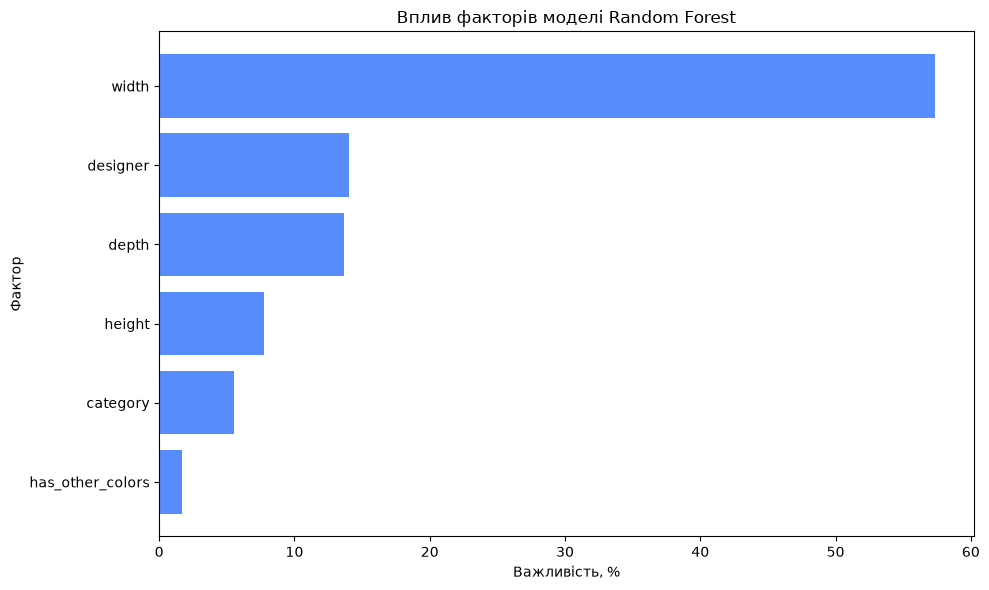

In [38]:
# Важливість факторів для Random Forest.
# One-Hot ознаки категорії групуємо назад у фактор category.
# Це дає зрозумілий огляд факторів, а не технічні Feature_0, Feature_1 тощо.

rf_model = best_rf_model.named_steps['model']
feature_importances = rf_model.feature_importances_
preprocessor_rf = best_rf_model.named_steps['preprocessor']

# Важливість числових факторів
factor_importance = {
    feature: feature_importances[i]
    for i, feature in enumerate(numeric_features)
}

offset = len(numeric_features)

# Важливість усіх One-Hot підфіч category об'єднуємо в один фактор
cat_encoder = preprocessor_rf.named_transformers_['cat'].named_steps['onehot']
n_category_features = len(cat_encoder.get_feature_names_out(categorical_features))

factor_importance['category'] = feature_importances[offset:offset + n_category_features].sum()

# Designer після target median encoding залишається однією ознакою
designer_index = offset + n_category_features
factor_importance['designer'] = feature_importances[designer_index]

importance_df = (
    pd.DataFrame(
        list(factor_importance.items()),
        columns=['Factor', 'Importance']
    )
    .sort_values('Importance', ascending=False)
)

importance_df['Importance_%'] = importance_df['Importance'] * 100

print("Важливість факторів Random Forest:")
display(importance_df)

plt.figure(figsize=(10, 6))
top_factors = importance_df.sort_values('Importance')

plt.barh(
    top_factors['Factor'],
    top_factors['Importance_%']
)

plt.title('Вплив факторів моделі Random Forest')
plt.xlabel('Важливість, %')
plt.ylabel('Фактор')

plt.tight_layout()
plt.show()


Крос-валідація фінальної моделі.

Для перевірки стабільності та узагальнюючої здатності фінальної моделі (після оптимізації гіперпараметрів) проведемо крос-валідацію за допомогою cross_val_score.Оцінка фінальної моделі + Cross-Validation



Результати 5-Fold Cross-Validation на train для: Random Forest з дефолтними гіперпараметрами


,Fold,RMSE,R2
0,1,674.116473,0.781982
1,2,664.364139,0.791178
2,3,592.424351,0.790977
3,4,684.460382,0.682546
4,5,672.254529,0.811290


Середній RMSE: 657.52 ± 33.17
Середній R²:    0.772 ± 0.046


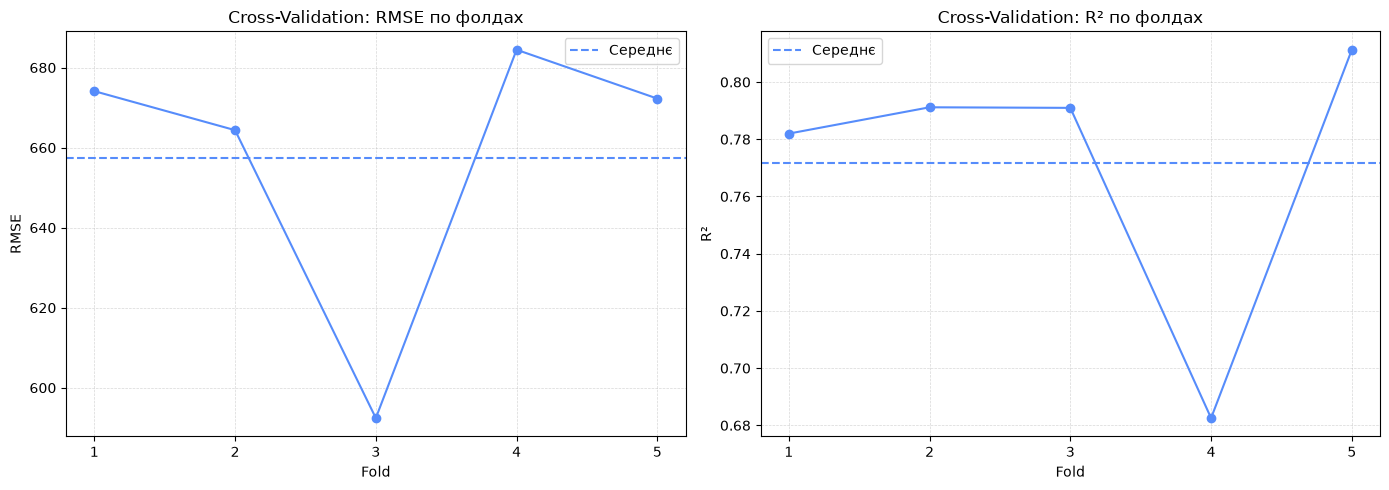

In [39]:
from sklearn.model_selection import cross_val_score

# ВАЖЛИВО: cross-validation виконуємо тільки на TRAIN.
# X_test та y_test залишаються незалежними для фінальної оцінки.
# Якщо GridSearch не покращив R², тут використовується дефолтна Random Forest.

cv_model = best_rf_model

rmse_scores = -cross_val_score(
    cv_model,
    X_train,
    y_train,
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

r2_scores = cross_val_score(
    cv_model,
    X_train,
    y_train,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

cv_results = pd.DataFrame({
    'Fold': np.arange(1, 6),
    'RMSE': rmse_scores,
    'R2': r2_scores
})

print(f"Результати 5-Fold Cross-Validation на train для: {final_model_type}")
display(cv_results)

print(f"Середній RMSE: {rmse_scores.mean():.2f} ± {rmse_scores.std():.2f}")
print(f"Середній R²:    {r2_scores.mean():.3f} ± {r2_scores.std():.3f}")

# Візуалізація стабільності CV.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

folds = np.arange(1, 6)

axes[0].plot(folds, cv_results['RMSE'], marker='o')
axes[0].axhline(rmse_scores.mean(), linestyle='--', label='Середнє')
axes[0].set_title('Cross-Validation: RMSE по фолдах')
axes[0].set_xlabel('Fold')
axes[0].set_ylabel('RMSE')
axes[0].set_xticks(folds)
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

axes[1].plot(folds, cv_results['R2'], marker='o')
axes[1].axhline(r2_scores.mean(), linestyle='--', label='Середнє')
axes[1].set_title('Cross-Validation: R² по фолдах')
axes[1].set_xlabel('Fold')
axes[1].set_ylabel('R²')
axes[1].set_xticks(folds)
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


Візуальна оцінка моделі: Фактичні vs Прогнозовані ціни

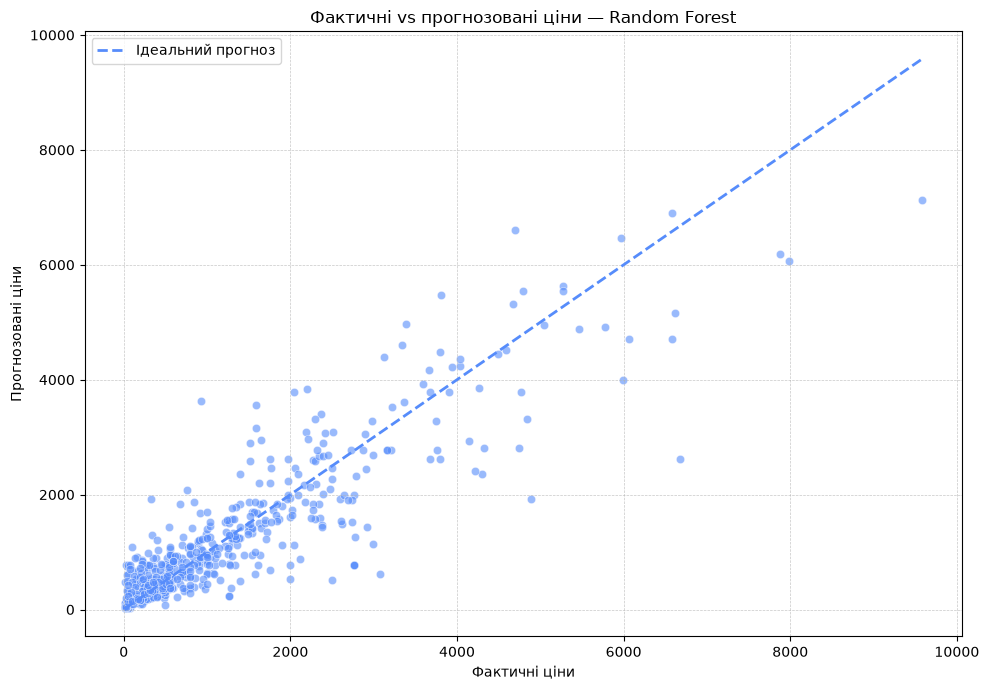

In [40]:
plt.figure(figsize=(10, 7))
sns.scatterplot(
    x=y_test,
    y=y_pred_best_rf,
    alpha=0.6
)

min_price = min(y_test.min(), y_pred_best_rf.min())
max_price = max(y_test.max(), y_pred_best_rf.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    '--',
    lw=2,
    label='Ідеальний прогноз'
)

plt.xlabel('Фактичні ціни')
plt.ylabel('Прогнозовані ціни')
plt.title('Фактичні vs прогнозовані ціни — Random Forest')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.tight_layout()
plt.show()


# Висновки за результатами аналізу датасету IKEA

## 1. Очищення та підготовка даних

На першому етапі було виконано очищення датасету. Технічні колонки та дублікати товарів було видалено, а проблемні значення у `designer` очищено. Колонку `old_price` приведено до числового формату, що дозволило коректно порівнювати стару та поточну ціни.

## 2. Перевірка гіпотези 1: наявність інших кольорів та ціна

Для товарів з іншими доступними кольорами медіанна ціна становить **695**, а для товарів без інших кольорів — **476**. Спостережувана різниця медіан дорівнює **219**.

Mann–Whitney U test та Welch t-test для логарифмованої ціни дали дуже малі `p-value`. Permutation test також показав **p = 0.00010**, тому на рівні значущості 0.05 нульову гіпотезу відхиляємо.

Важливе методологічне виправлення: перцентилі `null_diffs` з permutation test не є 95% довірчим інтервалом для справжньої різниці медіан. Тому в оновленому аналізі 95% CI обчислюється окремо за допомогою **bootstrap**.

Отже, permutation test відповідає на питання про статистичну значущість, а bootstrap CI — про невизначеність оцінки величини різниці.

## 3. Перевірка гіпотези 2: IKEA vs індивідуальні дизайнери

Медіанна ціна товарів IKEA становить **675**, а товарів індивідуальних дизайнерів — **545**. Різниця `Individual - IKEA` дорівнює **−130**.

Для сформульованої односторонньої альтернативи `Individual > IKEA` permutation test дав **p = 0.99900**. Отже, підстав відхиляти H₀ на користь твердження, що індивідуальні дизайнери мають вищу медіанну ціну, немає.

При цьому bootstrap CI для різниці медіан потрібно трактувати за його фактичним значенням: якщо весь інтервал нижче 0, це означає, що оцінена різниця має протилежний напрямок — медіанна ціна товарів індивідуальних дизайнерів нижча за IKEA. Таким чином, результати не підтверджують H₁, а вказують на протилежний напрямок різниці.

## 4. Машинне навчання

Для прогнозування `price` було побудовано Linear Regression, Random Forest та Gradient Boosting. Числові ознаки оброблялися через `SimpleImputer` та `StandardScaler`, категорія — через `OneHotEncoder`, а `designer` — через target median encoding.

Масштабування залишено в Pipeline як єдиний підхід до препроцесингу. Для Random Forest масштабування не є обов'язковим, але воно не заважає коректній роботі моделі в цьому Pipeline.

Серед базових моделей найкращою була **Random Forest Regressor**: `R² = 0.808`, `RMSE ≈ 602.05`, `MAE ≈ 361.38`.

## 5. Підбір гіперпараметрів

GridSearchCV підібрав такі параметри Random Forest:

- `n_estimators = 200`;
- `max_features = 0.5`;
- `max_depth = 30`;
- `min_samples_leaf = 2`.

Однак на тестовій вибірці налаштована модель отримала `R² ≈ 0.798`, тоді як базова Random Forest мала `R² ≈ 0.808`.

Тобто підбір гіперпараметрів **не покращив R²**. Згідно з рекомендацією, для подальшої cross-validation використовується Random Forest з **дефолтними гіперпараметрами**, а не tuned-модель.

## 6. Важливість факторів

Початкові назви `Feature_0`, `Feature_1`, `Feature_2` були замінені на зрозумілі назви факторів.

One-Hot підфічі категорії тепер **групуються назад у єдиний фактор `category`**. Тому результат показує вплив факторів, які відповідають оригінальним ознакам `X`:

- `category`;
- `designer`;
- `depth`;
- `height`;
- `width`;
- `has_other_colors`.

Це робить результат зрозумілішим для інтерпретації: замість десятків технічних dummy-ознак можна побачити загальний внесок кожного фактора.

Важливість Random Forest слід трактувати як внесок ознаки у прогноз моделі, а не як доказ причинно-наслідкового зв'язку.

## 7. Крос-валідація

Для фінальної перевірки використовується 5-Fold Cross-Validation тільки на тренувальній вибірці. Тестова вибірка залишається незалежною для фінальної оцінки.

Якщо GridSearch не покращив R², як у цьому аналізі, cross-validation виконується для дефолтної Random Forest.

На графіках крос-валідації по осі X встановлені лише цілі значення `1, 2, 3, 4, 5`, що відповідають п'яти фолдам.

